# CMS HH to four b open data: jets in the three-tag data sample

This notebook reads one file of the three-tag data sample of the CMS HH to four b open-data release ([record cms-93965](https://opendata.cern.ch/record/cms-93965)). The plots show the transverse momentum and pseudorapidity of the two highest-momentum jets in each event, and the number of selected jets per event.

In [ ]:
%pip install -q pandas numpy matplotlib pyarrow fsspec aiohttp mplhep torch scikit-learn

In [22]:
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

hep.style.use("CMS")

In [23]:
# Configuration
DATA_URL = "https://opendata.cern.ch/eos/opendata/cms/HH4b_mixeddatasets/data/3b/part_UL16_postVFP_F.parquet"  # load a single 3b data file
BACKGROUND_URL = "https://opendata.cern.ch/eos/opendata/cms/HH4b_mixeddatasets/mixeddata_all/4b/part_UL16_postVFP_F_1.parquet" # load a single mixed background file
COLUMNS = ["Jet1_pt", "Jet1_eta", "Jet2_pt", "Jet2_eta", "nSelJets", "SR"]

In [24]:
data = pd.read_parquet(DATA_URL, columns=COLUMNS)
background = pd.read_parquet(BACKGROUND_URL, columns=COLUMNS)
print(f"Events read: {len(data):,} signal, {len(background):,} background")

Events read: 111,677 signal, 44,800 background


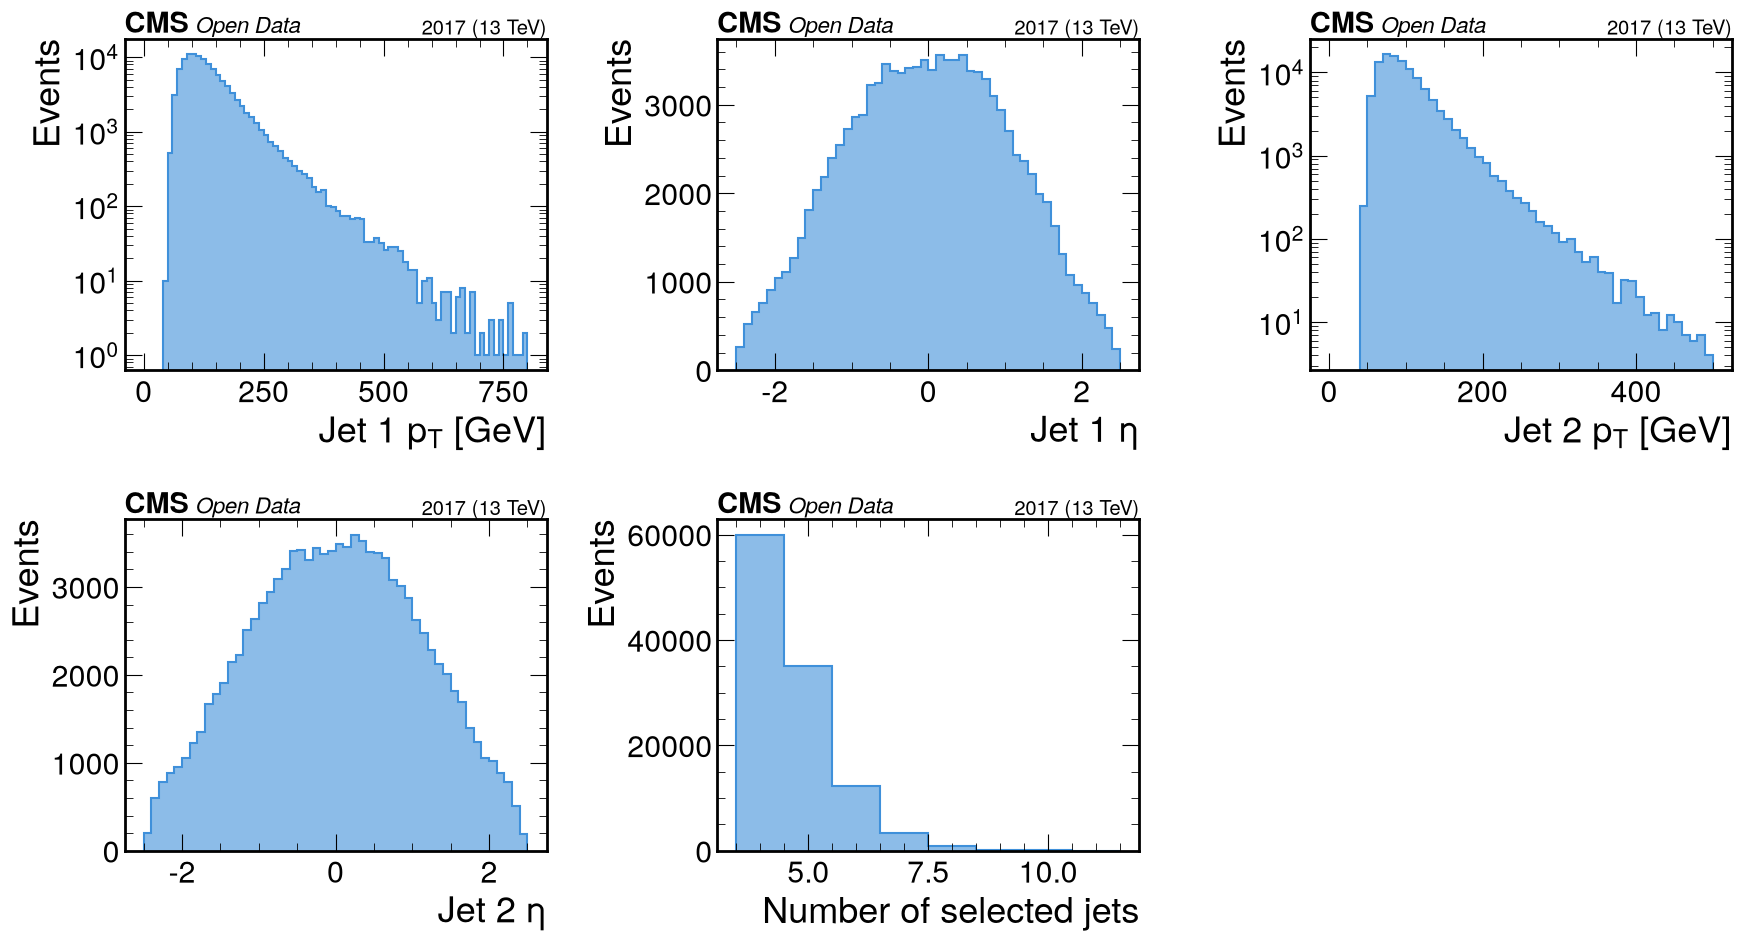

In [25]:
# make some plots from the data file
pt1_bins = np.linspace(0, 800, 81)
pt2_bins = np.linspace(0, 500, 51)
eta_bins = np.linspace(-2.5, 2.5, 51)
n_bins = np.arange(3.5, 12.5, 1)
COLOR = "#3f90da"

panels = [
    ("Jet1_pt", pt1_bins, "Jet 1 $p_T$ [GeV]", True),
    ("Jet1_eta", eta_bins, "Jet 1 $\\eta$", False),
    ("Jet2_pt", pt2_bins, "Jet 2 $p_T$ [GeV]", True),
    ("Jet2_eta", eta_bins, "Jet 2 $\\eta$", False),
    ("nSelJets", n_bins, "Number of selected jets", False),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (column, bins, label, logy) in zip(axes.flat, panels):
    counts, _ = np.histogram(data[column], bins=bins)
    hep.histplot(counts, bins, ax=ax, histtype="fill", alpha=0.6, color=COLOR)
    hep.histplot(counts, bins, ax=ax, histtype="step", color=COLOR)
    ax.set_xlabel(label)
    ax.set_ylabel("Events")
    if logy:
        ax.set_yscale("log")
    hep.cms.label(ax=ax, text="Open Data", data=True, rlabel="2017 (13 TeV)", loc=0, fontsize=16)
axes.flat[5].axis("off")
fig.tight_layout()
plt.show()

The same five plots can be made for any other file of the release by changing the dataset location in the configuration cell.

In [26]:
# filter signal region events
data_inputs = data[data.SR == True].drop(["SR"], axis=1)
background_inputs = background[background.SR == True].drop(["SR"], axis=1)
print(data_inputs, background_inputs)

         Jet1_pt  Jet1_eta   Jet2_pt  Jet2_eta  nSelJets
0        70.6875  1.223145   67.8750  1.584473         4
2       109.0000  0.715454   93.3125  1.118652         5
3       118.4375 -1.278809   71.6250 -0.655396         5
6        96.8125  0.415894   86.0625  0.103973         4
9       199.2500 -0.175934  148.8750 -0.783691         4
...          ...       ...       ...       ...       ...
111662  150.1250  1.220703  113.5000 -0.107330         4
111665  114.3750 -0.227783   80.3750 -0.045265         6
111667   79.3125  0.622803   63.6250 -0.823120         5
111668  210.6250 -0.729980  187.7500 -0.089951         6
111676  425.5000 -0.366211  131.3750 -2.753906         5

[42119 rows x 5 columns]           Jet1_pt  Jet1_eta     Jet2_pt  Jet2_eta  nSelJets
0       75.765221  1.195557   64.821892  0.329224         4
1      230.308273  0.299622  192.578171 -2.579102         8
3       87.465324 -2.128906   66.629181 -0.054199         4
6      113.040916  0.806396   67.766891  0.808960 

In [27]:
# turn into pytorch tensors for ML training and split into train/test datasets
x_data = torch.tensor(data_inputs.values, dtype=torch.float32)
x_background = torch.tensor(background_inputs.values, dtype=torch.float32)

y_data = torch.ones(len(x_data), dtype=torch.float32)
y_background = torch.zeros(len(x_background), dtype=torch.float32)

X = torch.cat([x_data, x_background], dim=0)
Y = torch.cat([y_data, y_background], dim=0)

X_train, X_test, Y_train, Y_test = train_test_split(X, 
                                                    Y, 
                                                    test_size=0.2, # 20% test, 80% train
                                                    random_state=42) # make the random split reproducible

# standardise each input with the mean and standard deviation of the training set
x_mean = X_train.mean(dim=0)
x_std = X_train.std(dim=0)
X_train = (X_train - x_mean) / x_std
X_test = (X_test - x_mean) / x_std

# per-event weights: each class sums to 1 over its set, so data and background enter the loss equally
def class_weights(y):
    w = torch.empty_like(y)
    w[y == 1] = 1.0 / (y == 1).sum()
    w[y == 0] = 1.0 / (y == 0).sum()
    return w

W_train = class_weights(Y_train)
W_test = class_weights(Y_test)

In [28]:
# define a simple neural network with 5 hidden layers
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

loss_fn = nn.BCEWithLogitsLoss(reduction="none")  # per-event loss, weighted and summed in the training loop

In [29]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [30]:
model = NeuralNetwork().to(device)
optimizer = torch.optim.SGD(params=model.parameters(), lr=0.1)
X_train, X_test, Y_train, Y_test, W_train, W_test = (t.to(device) for t in (X_train, X_test, Y_train, Y_test, W_train, W_test))

torch.manual_seed(42)
epochs = 100

# Build training and evaluation loop
for epoch in range(epochs):
    # Training
    model.train()

    # 1. Forward pass
    y_logits = model(X_train).squeeze()

    # 2. Calculate loss
    loss = (loss_fn(y_logits, Y_train) * W_train).sum() # BCEWithLogitsLoss applies the sigmoid itself

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backwards
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    # Testing
    model.eval()
    with torch.inference_mode():
        # 1. Forward pass
        test_logits = model(X_test).squeeze()
        # 2. Calculate loss
        test_loss = (loss_fn(test_logits, Y_test) * W_test).sum()
        # 3. Calculate the test AUC from the ranking of the predicted probabilities
        test_auc = roc_auc_score(Y_test.cpu().numpy(), torch.sigmoid(test_logits).cpu().numpy())

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test loss: {test_loss:.5f}, Test AUC: {test_auc:.4f}")

Epoch: 0 | Loss: 1.39720 | Test loss: 1.38940, Test AUC: 0.5233
Epoch: 10 | Loss: 1.34035 | Test loss: 1.33648, Test AUC: 0.7386
Epoch: 20 | Loss: 1.29330 | Test loss: 1.29069, Test AUC: 0.7484
Epoch: 30 | Loss: 1.24758 | Test loss: 1.24585, Test AUC: 0.7617
Epoch: 40 | Loss: 1.20468 | Test loss: 1.20355, Test AUC: 0.7776
Epoch: 50 | Loss: 1.16622 | Test loss: 1.16526, Test AUC: 0.7930
Epoch: 60 | Loss: 1.13356 | Test loss: 1.13232, Test AUC: 0.8038
Epoch: 70 | Loss: 1.10798 | Test loss: 1.10626, Test AUC: 0.8103
Epoch: 80 | Loss: 1.08959 | Test loss: 1.08730, Test AUC: 0.8139
Epoch: 90 | Loss: 1.07700 | Test loss: 1.07414, Test AUC: 0.8159


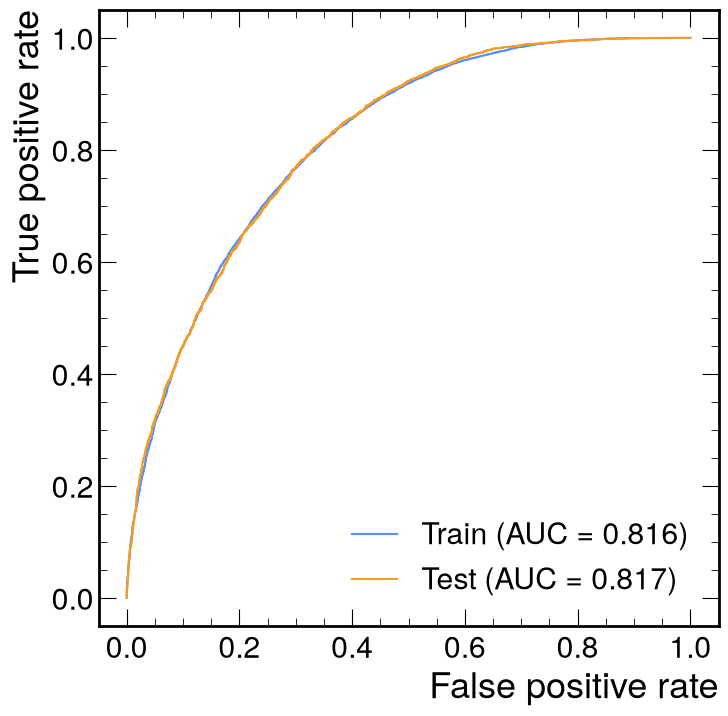

In [31]:
# ROC curves of the trained network on the training and test sets
model.eval()
with torch.inference_mode():
    p_train = torch.sigmoid(model(X_train).squeeze()).cpu().numpy()
    p_test = torch.sigmoid(model(X_test).squeeze()).cpu().numpy()
y_train_np = Y_train.cpu().numpy()
y_test_np = Y_test.cpu().numpy()

fig, ax = plt.subplots(figsize=(8, 8))
for name, y_true, p in [("Train", y_train_np, p_train), ("Test", y_test_np, p_test)]:
    fpr, tpr, _ = roc_curve(y_true, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_true, p):.3f})")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
plt.show()